In [1]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from ml_from_scratch.linear_regression import LinearRegression
from ml_from_scratch.preprocessing import StandardScaler

X, y = fetch_california_housing(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

model_gd = LinearRegression(method='gd', lr=0.1, n_iters=1000).fit(X_train_s, y_train)
model_normal = LinearRegression(method='normal').fit(X_train_s, y_train)

print(model_gd.loss_history_[:5], '\n', model_gd.loss_history_[-1])
print(model_normal.intercept_, '\n', model_normal.coef_)
print(model_gd.intercept_, '\n', model_gd.coef_)

[np.float64(5.629742323103131), np.float64(3.8271884682773276), np.float64(2.6786763832436766), np.float64(1.944725739933717), np.float64(1.4744853124191133)] 
 0.517933125598221
2.071946937378613 
 [ 0.85438303  0.12254624 -0.29441013  0.33925949 -0.00230772 -0.0408291
 -0.89692888 -0.86984178]
2.0719469373786192 
 [ 0.85439252  0.12254819 -0.29442715  0.33927328 -0.00230712 -0.04082953
 -0.89690651 -0.86982051]


In [2]:
from ml_from_scratch.metrics import rmse, r2_score

for name, model in [('normal', model_normal), ('gd', model_gd)]:
	print(name,
			'train R²:', r2_score(y_train, model.predict(X_train_s)),
			'test R²:', r2_score(y_test, model.predict(X_test_s)),
			'test RMSE:', rmse(y_test, model.predict(X_test_s)))

normal train R²: 0.6125511913966952 test R²: 0.5757877060324511 test RMSE: 0.7455813830127761
gd train R²: 0.6125511913427097 test R²: 0.5757868996916564 test RMSE: 0.7455820916112864


In [3]:
from sklearn.linear_model import Ridge

sk = Ridge(alpha=10).fit(X_train_s, y_train)
my_model_normal = LinearRegression(method='normal', alpha=10).fit(X_train_s, y_train)
my_model_grad = LinearRegression(method='gd', lr=0.1, alpha=10).fit(X_train_s, y_train)

print(sk.intercept_, sk.coef_)
print(my_model_normal.intercept_, my_model_normal.coef_)
print(my_model_grad.intercept_, my_model_grad.coef_)

2.071946937378621 [ 0.85381377  0.12331557 -0.2924118   0.33674955 -0.0020552  -0.04086734
 -0.88938399 -0.86219926]
2.0719469373786152 [ 0.85381377  0.12331557 -0.2924118   0.33674955 -0.0020552  -0.04086734
 -0.88938399 -0.86219926]
2.071946937378622 [ 0.85382206  0.12331728 -0.29242666  0.3367616  -0.00205467 -0.04086771
 -0.88936444 -0.86218068]


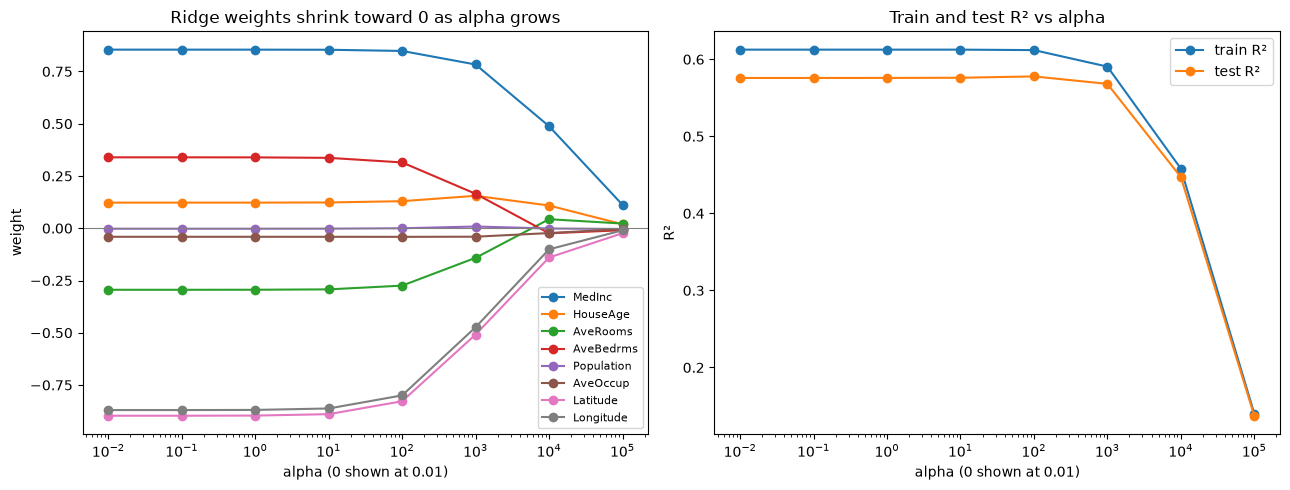

alpha=      0: train R² 0.6126, test R² 0.5758
alpha=    0.1: train R² 0.6126, test R² 0.5758
alpha=      1: train R² 0.6126, test R² 0.5758
alpha=     10: train R² 0.6125, test R² 0.5761
alpha=    100: train R² 0.6120, test R² 0.5778
alpha=   1000: train R² 0.5905, test R² 0.5681
alpha=  10000: train R² 0.4582, test R² 0.4472
alpha= 100000: train R² 0.1400, test R² 0.1373


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from ml_from_scratch.linear_regression import LinearRegression
from ml_from_scratch.metrics import r2_score

feature_names = fetch_california_housing().feature_names
alphas = [0, 0.1, 1, 10, 100, 1000, 10000, 100000]

coefs, train_r2, test_r2 = [], [], []
for a in alphas:
	model = LinearRegression(method='normal', alpha=a).fit(X_train_s, y_train)
	coefs.append(model.coef_)
	train_r2.append(r2_score(y_train, model.predict(X_train_s)))
	test_r2.append(r2_score(y_test, model.predict(X_test_s)))

coefs = np.array(coefs)

# α = 0 can't be shown on a log scale, so plot it at a small stand-in value
plot_alphas = [1e-2 if a == 0 else a for a in alphas]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for j, name in enumerate(feature_names):
	axes[0].plot(plot_alphas, coefs[:, j], marker='o', label=name)
axes[0].axhline(0, color='grey', linewidth=0.8)
axes[0].set_xscale('log')
axes[0].set_xlabel('alpha (0 shown at 0.01)')
axes[0].set_ylabel('weight')
axes[0].set_title('Ridge weights shrink toward 0 as alpha grows')
axes[0].legend(fontsize=8)

axes[1].plot(plot_alphas, train_r2, marker='o', label='train R²')
axes[1].plot(plot_alphas, test_r2, marker='o', label='test R²')
axes[1].set_xscale('log')
axes[1].set_xlabel('alpha (0 shown at 0.01)')
axes[1].set_ylabel('R²')
axes[1].set_title('Train and test R² vs alpha')
axes[1].legend()

plt.tight_layout()
plt.show()

for a, tr, te in zip(alphas, train_r2, test_r2):
	print(f"alpha={a:>7}: train R² {tr:.4f}, test R² {te:.4f}")